# Análise exploratória espacial de dengue e saneamento com PySAL

## tl;dr

- O contrato de 2022 usa uma grade municipal completa e identifica explicitamente municípios **com** e **sem notificação registrada**.
- A unidade geográfica do SINAN é o **município de residência**. Na ausência de notificação registrada, contagens e taxas permanecem iguais a zero quando há denominador populacional válido.
- A auditoria abaixo verifica separadamente as coberturas de população, saneamento e geometria antes de construir os pesos espaciais.
- Na coorte restaurada, os 5.570 municípios apresentam autocorrelação global positiva; nenhum cluster LISA local é significativo após FDR-BY a 5%.
- As associações calculadas são ecológicas e exploratórias; por si só, **não demonstram causalidade**.

**Período anual:** `ano` nos contratos SINAN identifica o ano-fonte (`periodo_referencia = ano_fonte_sinan`), não necessariamente um ano civil completo. Datas em anos adjacentes são preservadas e auditadas. A população usa o ano de referência; as séries diárias climáticas permanecem separadas, pela data efetiva de notificação.

## Contexto e métodos

O notebook combina `sinan/processados/sinan_saneamento_2022.parquet` com a malha municipal simplificada fornecida pela API de Malhas do IBGE. A análise usa o ecossistema PySAL:

- `libpysal.weights.KNN` para a matriz de pesos espaciais;
- `esda.Moran`, `esda.Moran_BV` e `esda.Moran_Local` para autocorrelação global, bivariada e local;
- `splot.esda` para os diagramas de Moran e o mapa LISA;
- `mapclassify`, por meio do GeoPandas, para o mapa coroplético quantílico.

### Principais premissas

1. A unidade de análise é o município de residência em 2022.
2. Os pesos usam os oito centroides municipais mais próximos (`KNN`, `k=8`) em `EPSG:5880`, uma projeção métrica para o Brasil, e são padronizados por linha.
3. KNN mantém o mesmo número de vizinhos por município e é construído somente depois da auditoria das coberturas necessárias.
4. Ausência de notificação registrada é uma categoria explícita do contrato, não uma linha ausente inferida pelo `merge`; esses municípios participam da análise com taxa zero quando elegíveis.
5. A inferência usa 999 permutações com sementes fixas. `p_sim = 0,001` é o menor valor possível com esse número de permutações.
6. A análise é exploratória, espacial e ecológica; não controla urbanização, estrutura etária, acesso ao diagnóstico ou subnotificação. Os dados climáticos permanecem fora deste contrato por enquanto.

## Dados

### 1. Preparar o ambiente e os parâmetros

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "utils/analysis_pipeline.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import polars as pl
from IPython.display import display

from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from utils import spatial_analysis as spatial

warnings.filterwarnings(
    "ignore",
    message="Casting complex values to real discards the imaginary part",
)

DATA_PATH = PROJECT_ROOT / "sinan/processados/sinan_saneamento_2022.parquet"
BOUNDARY_PATH = spatial.DEFAULT_BOUNDARY_PATH
FIGURE_DIR = PROJECT_ROOT / "figuras/analise_espacial"
RESULT_DIR = PROJECT_ROOT / "sinan/processados/analise_espacial"

K_NEIGHBORS = 8
PERMUTATIONS = 999
SEED = 42
ALPHA = 0.05

pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

### 2. Carregar a malha e auditar a integração

In [2]:
full_map, analysis_map, geographic_audit = spatial.load_spatial_data(
    data_path=DATA_PATH,
    boundary_path=BOUNDARY_PATH,
)

display(
    geographic_audit.style.format(
        {"valor": lambda value: f"{value:,.2f}" if value % 1 else f"{value:,.0f}"}
    )
)

notification_summary = (
    full_map.groupby(
        ["tem_notificacao_registrada", "situacao_registro_sinan"],
        dropna=False,
    )
    .size()
    .rename("municipios")
    .reset_index()
)
display(notification_summary)

,metrica,valor
0,municipios_malha,"5,570"
1,municipios_base_analitica,"5,570"
2,registros_codigo_municipio_invalido,0
3,municipios_com_notificacao_registrada,"5,017"
4,municipios_sem_notificacao_registrada,553
5,municipios_com_populacao,"5,570"
6,cobertura_percentual_populacao,100
7,municipios_com_saneamento,"5,570"
8,cobertura_percentual_saneamento,100
9,municipios_com_geometria,"5,570"


,tem_notificacao_registrada,situacao_registro_sinan,municipios
0,False,sem_notificacao_registrada,553
1,True,com_notificacao_registrada,5017


A auditoria conta as duas situações de notificação a partir da flag fornecida pelo pipeline e mostra, separadamente, quantos municípios têm população, saneamento e geometria utilizáveis. Códigos inválidos são contabilizados, mas excluídos da análise espacial.

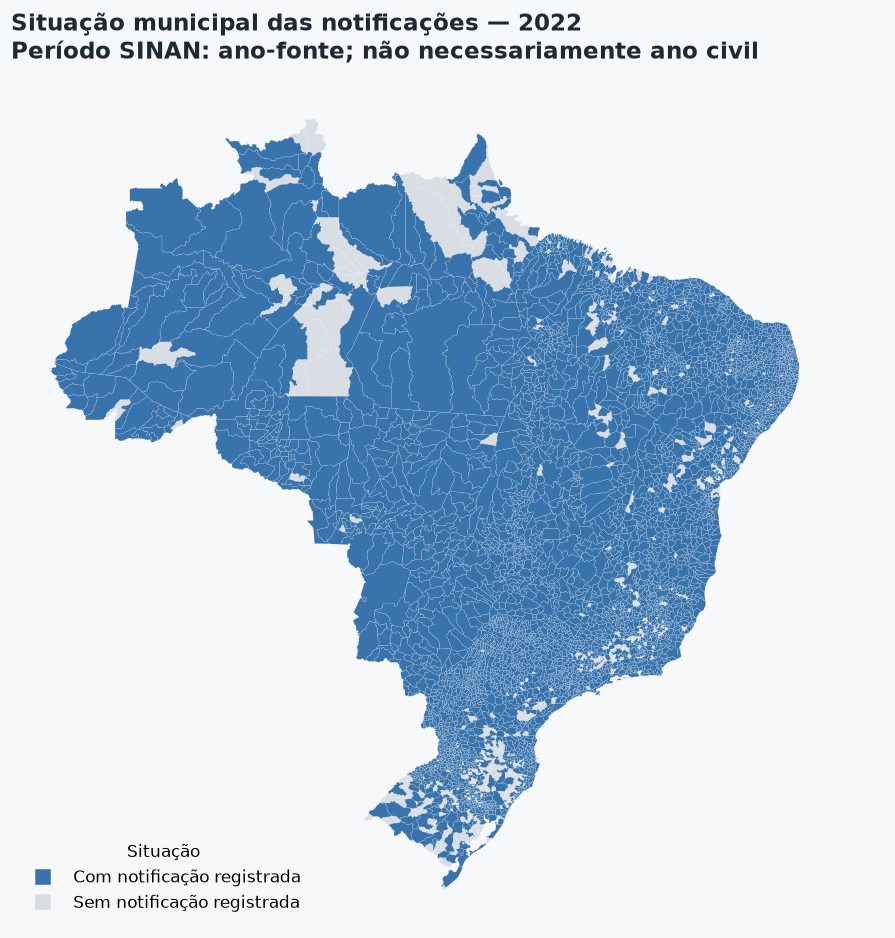

In [3]:
coverage_figure, _ = spatial.plot_data_coverage(full_map)
spatial.save_figure(coverage_figure, FIGURE_DIR / "01_cobertura_sinan_2022.png")
plt.show()

### 3. Construir e verificar os pesos espaciais

In [4]:
weights = spatial.build_knn_weights(analysis_map, k=K_NEIGHBORS)

weights_summary = pd.DataFrame(
    {
        "observacoes": [weights.n],
        "vizinhos_por_municipio": [K_NEIGHBORS],
        "ilhas": [len(weights.islands)],
        "transformacao": [weights.transform],
    }
)
display(weights_summary)

,observacoes,vizinhos_por_municipio,ilhas,transformacao
0,5570,8,0,R


## Resultados

### 4. Distribuição geográfica da taxa de dengue

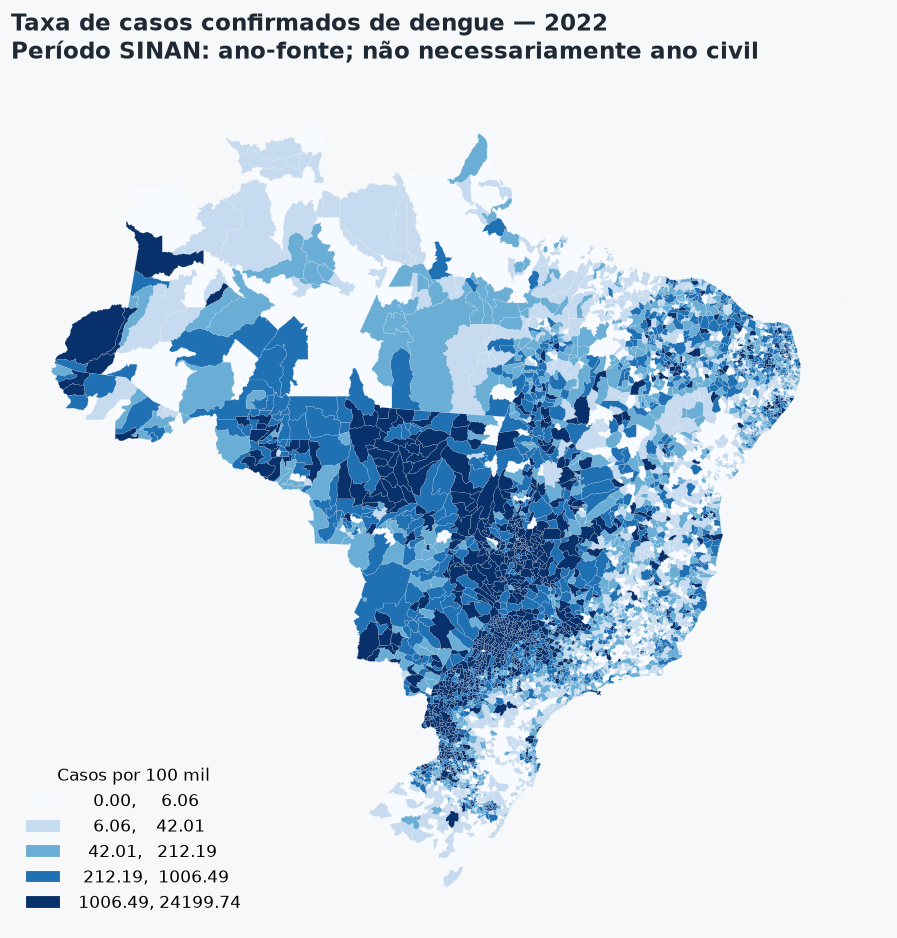

In [5]:
rate_figure, _ = spatial.plot_rate_choropleth(full_map)
spatial.save_figure(rate_figure, FIGURE_DIR / "02_taxa_confirmados_2022.png")
plt.show()

O mapa usa quintis, não faixas epidemiológicas normativas nem classes de significância. Municípios sem notificação registrada entram com taxa zero; cinza indica dado indisponível. Cores próximas no mapa não demonstram, por si só, um cluster significativo.

### 5. Autocorrelação espacial global

In [6]:
global_moran, global_models = spatial.calculate_global_moran(
    analysis_map,
    weights,
    permutations=PERMUTATIONS,
    seed=SEED,
)

display(
    global_moran[
        ["indicador", "n", "media", "desvio_padrao", "moran_i", "p_sim_bilateral"]
    ].style.format(
        {
            "media": "{:.2f}",
            "desvio_padrao": "{:.2f}",
            "moran_i": "{:.3f}",
            "p_sim": "{:.3f}",
        }
    )
)

,indicador,n,media,desvio_padrao,moran_i,p_sim_bilateral
0,Casos confirmados de dengue por 100 mil habitantes,5570,878.60,2116.86,0.431,0.002000
1,Domicílios com rede geral como principal abastecimento (%),5570,71.72,19.60,0.478,0.002000
2,Domicílios com esgoto em rede geral ou pluvial (%),5570,34.27,32.85,0.716,0.002000
3,Domicílios com lixo coletado no domicílio (%),5570,72.44,20.01,0.469,0.002000


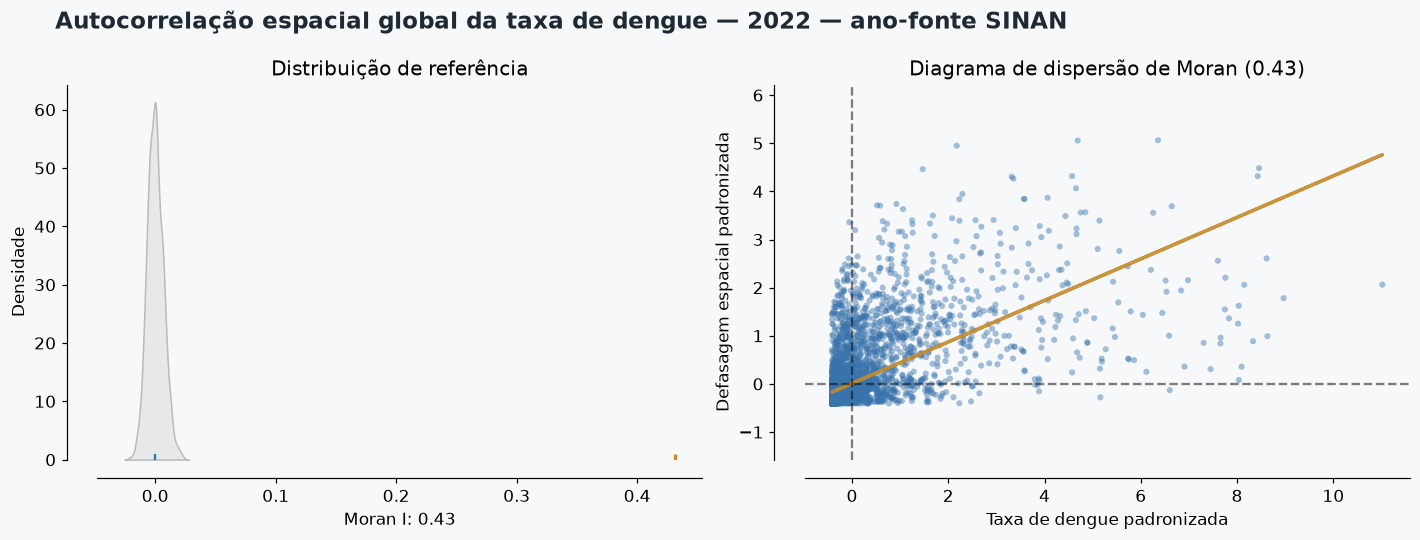

In [7]:
moran_figure, _ = spatial.plot_global_moran_result(
    global_models["taxa_confirmados_100k"],
    "Autocorrelação espacial global da taxa de dengue — 2022",
)
spatial.save_figure(moran_figure, FIGURE_DIR / "03_moran_global_taxa_2022.png")
plt.show()

Em 2022, há autocorrelação espacial global positiva da taxa de dengue: I = 0,4313 e p bilateral por permutação = 0,002, com 5.570 municípios. O teste identifica um padrão global, mas não localiza clusters nem explica suas causas.

### 6. Sensibilidade ao número de vizinhos

In [8]:
knn_sensitivity = spatial.calculate_knn_sensitivity(
    analysis_map,
    neighbors=(4, 8, 12, 16),
    permutations=PERMUTATIONS,
    seed=SEED + 300,
)
display(knn_sensitivity.style.format({"moran_i": "{:.3f}", "p_sim": "{:.3f}", "z_sim": "{:.2f}"}))

,k_vizinhos,moran_i,p_sim,p_sim_bilateral,z_sim,permutacoes
0,4,0.474,0.001,0.002000,51.17,999
1,8,0.431,0.001,0.002000,68.25,999
2,12,0.422,0.001,0.002000,80.81,999
3,16,0.410,0.001,0.002000,92.42,999


O resultado global é estável para k = 4, 8, 12 e 16: I varia de 0,4104 a 0,4740, sempre positivo, com p bilateral = 0,002. Portanto, o padrão observado não depende apenas de k = 8.

### Sensibilidade à população

O ajuste de Assunção–Reis mantém o Moran global positivo (I = 0,4312; p bilateral = 0,002). Também não há clusters locais significativos após FDR-BY nas taxas ajustadas. Esses resultados não eliminam subnotificação ou confundimento.

In [9]:
rate_sensitivity, rate_local = spatial.calculate_rate_sensitivity(
    analysis_map, weights, permutations=PERMUTATIONS, seed=SEED + 400, alpha=ALPHA
)
display(rate_sensitivity)
display(rate_local.head())

,metodo,moran_i,p_sim,permutacoes,p_sim_bilateral,alpha
0,Assuncao-Reis,0.431208,0.001,999,0.002,0.05


,codigo_municipio,lisa_taxa_ajustada_i,lisa_taxa_ajustada_p_sim,lisa_taxa_ajustada_p_by,lisa_taxa_ajustada_quadrante,alpha
0,110001,0.069072,0.499,1.0,0,0.05
1,110002,0.006584,0.623,1.0,0,0.05
2,110003,0.083934,0.435,1.0,0,0.05
3,110004,0.019685,0.687,1.0,0,0.05
4,110005,0.077889,0.561,1.0,0,0.05


### 7. Autocorrelação local — LISA

In [10]:
lisa_map, local_moran = spatial.calculate_local_moran(
    analysis_map,
    weights,
    variable="taxa_confirmados_100k",
    permutations=PERMUTATIONS,
    seed=SEED + 200,
    alpha=ALPHA,
)

cluster_order = [
    "Alto–Alto",
    "Baixo–Baixo",
    "Baixo–Alto",
    "Alto–Baixo",
    "Não significativo",
]
cluster_summary = (
    lisa_map["lisa_cluster"]
    .value_counts()
    .reindex(cluster_order, fill_value=0)
    .rename_axis("cluster")
    .reset_index(name="municipios")
)
display(cluster_summary)

,cluster,municipios
0,Alto–Alto,0
1,Baixo–Baixo,0
2,Baixo–Alto,0
3,Alto–Baixo,0
4,Não significativo,5570


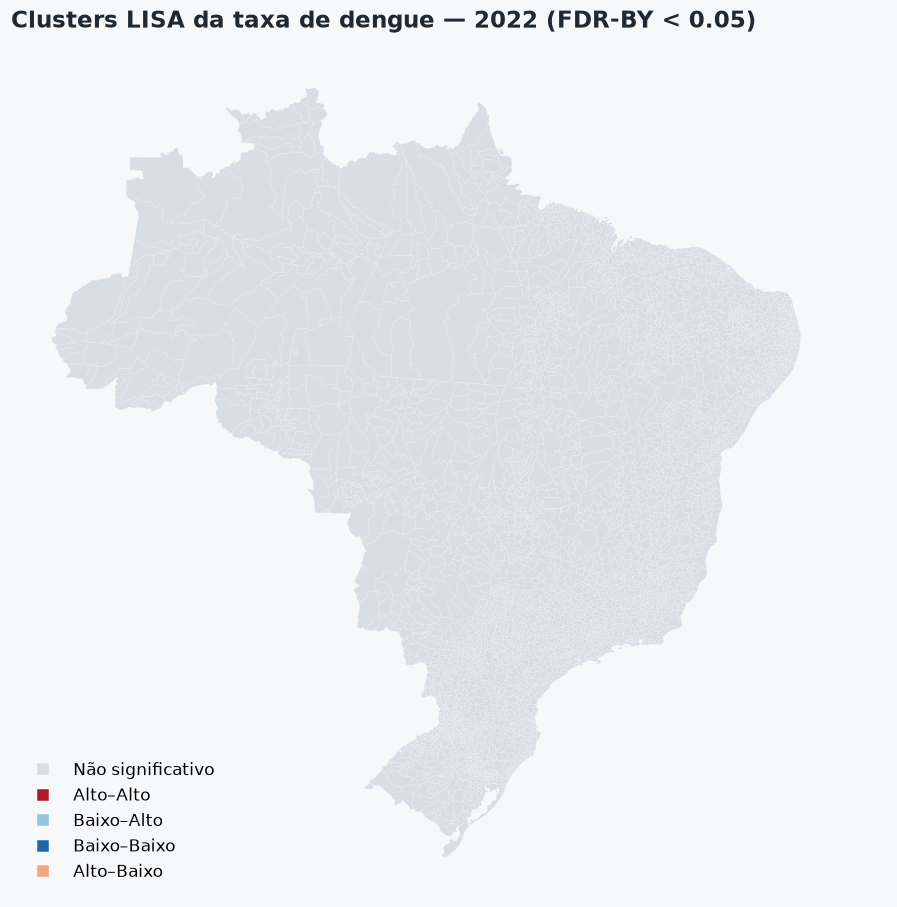

In [11]:
lisa_figure, _ = spatial.plot_lisa_clusters(
    full_map,
    lisa_map,
    local_moran,
    alpha=ALPHA,
)
spatial.save_figure(lisa_figure, FIGURE_DIR / "04_lisa_taxa_2022.png")
plt.show()

Nenhum dos 5.570 municípios apresenta LISA significativo após o teste bilateral e a correção FDR-BY a 5%. Não há clusters Alto–Alto, Baixo–Baixo, Alto–Baixo ou Baixo–Alto significativos para localizar ou destacar nesta execução. A tabela de Alto–Alto abaixo está vazia por esse motivo. Isso não contradiz a autocorrelação global positiva: os testes avaliam hipóteses diferentes.

In [12]:
high_high = (
    lisa_map.loc[lisa_map["lisa_cluster"].eq("Alto–Alto")]
    .nlargest(10, "taxa_confirmados_100k")
    [["municipio", "taxa_confirmados_100k", "lisa_i", "lisa_p_sim", "lisa_p_ajustado_by"]]
)
display(
    high_high.style.format(
        {
            "taxa_confirmados_100k": "{:.1f}",
            "lisa_i": "{:.3f}",
            "lisa_p_sim": "{:.3f}",
        }
    )
)

,municipio,taxa_confirmados_100k,lisa_i,lisa_p_sim,lisa_p_ajustado_by


### 8. Moran bivariado: dengue local e saneamento da vizinhança

In [13]:
bivariate_moran, bivariate_models = spatial.calculate_bivariate_moran(
    analysis_map,
    weights,
    permutations=PERMUTATIONS,
    seed=SEED + 100,
)
display(
    bivariate_moran[
        ["indicador_vizinhanca", "n", "moran_bivariado_i", "p_sim_bilateral"]
    ].style.format({"moran_bivariado_i": "{:.3f}", "p_sim": "{:.3f}"})
)

,indicador_vizinhanca,n,moran_bivariado_i,p_sim_bilateral
0,Domicílios com rede geral como principal abastecimento (%),5570,0.144,0.002000
1,Domicílios com esgoto em rede geral ou pluvial (%),5570,0.115,0.002000
2,Domicílios com lixo coletado no domicílio (%),5570,0.165,0.002000


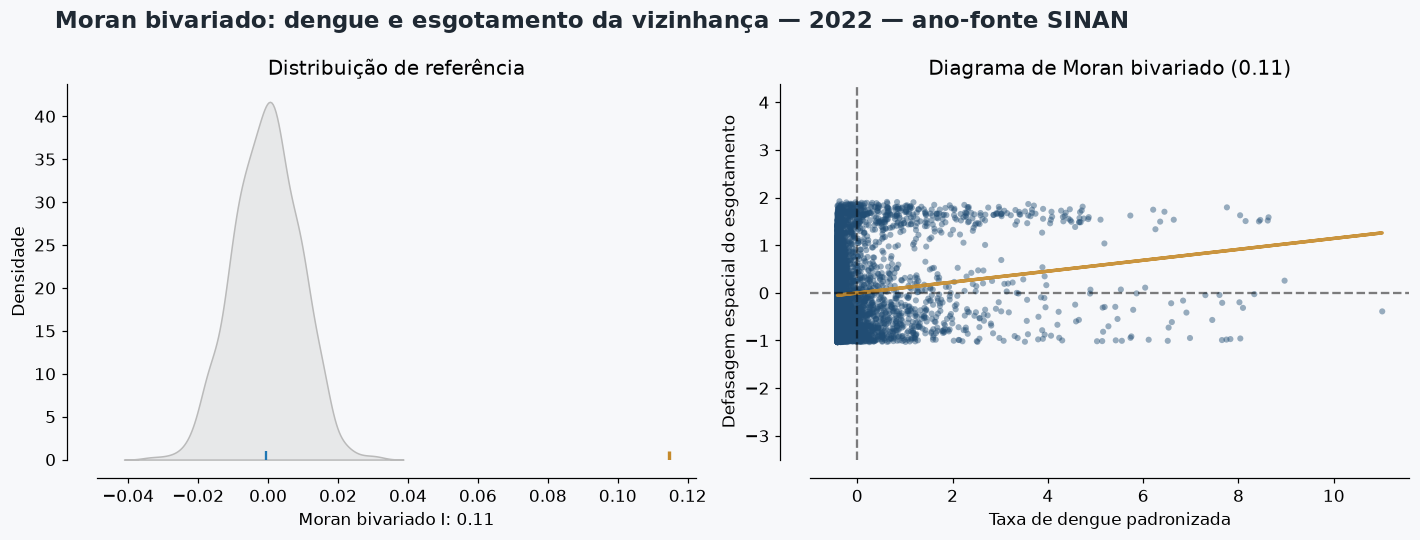

In [14]:
bivariate_figure, _ = spatial.plot_bivariate_moran_result(
    bivariate_models["pct_esgoto_rede_geral_ou_pluvial"],
    "Moran bivariado: dengue e esgotamento da vizinhança — 2022",
)
spatial.save_figure(
    bivariate_figure,
    FIGURE_DIR / "05_moran_bivariado_esgoto_2022.png",
)
plt.show()

As associações espaciais bivariadas são positivas e de baixa magnitude: água I = 0,1441, esgoto I = 0,1146 e coleta de lixo I = 0,1651, com p bilateral = 0,002 em cada análise exploratória. Isso não demonstra efeito protetor ou prejudicial do saneamento; urbanização, diagnóstico e outros fatores podem explicar as associações.

### 9. Salvar tabelas reproduzíveis

In [15]:
RESULT_DIR.mkdir(parents=True, exist_ok=True)
geographic_audit.to_csv(RESULT_DIR / "auditoria_geografica_2022.csv", index=False)
global_moran.to_csv(RESULT_DIR / "moran_global_2022.csv", index=False)
bivariate_moran.to_csv(RESULT_DIR / "moran_bivariado_2022.csv", index=False)
knn_sensitivity.to_csv(RESULT_DIR / "sensibilidade_knn_2022.csv", index=False)
rate_sensitivity.to_csv(RESULT_DIR / "sensibilidade_taxa_ajustada_2022.csv", index=False)
rate_local.to_csv(RESULT_DIR / "lisa_taxa_ajustada_2022.csv", index=False)
lisa_map.drop(columns="geometry").to_csv(
    RESULT_DIR / "lisa_taxa_confirmados_2022.csv",
    index=False,
)

sorted(path.name for path in FIGURE_DIR.glob("*.png"))

['01_cobertura_sinan_2022.png',
 '02_taxa_confirmados_2022.png',
 '03_moran_global_taxa_2022.png',
 '04_lisa_taxa_2022.png',
 '05_moran_bivariado_esgoto_2022.png']

## Conclusões

1. A análise cobre os 5.570 municípios, com população, saneamento e geometria disponíveis. O período é o ano-fonte SINAN de 2022, não necessariamente um ano civil completo.
2. Há autocorrelação global positiva (I = 0,4313; p bilateral = 0,002), estável nas quatro configurações KNN e após ajuste da taxa à população.
3. Nenhum cluster LISA local permanece significativo após FDR-BY a 5%, tanto na taxa bruta quanto na ajustada. Não se sustentam as antigas identificações de clusters municipais significativos.
4. As associações com saneamento são fracas e exploratórias. Não demonstram causalidade, proteção ou aumento de risco causado pelo saneamento.

A ausência de descobertas locais não prova ausência de agrupamento espacial. O resultado global e o local devem ser interpretados separadamente.

### Reexecução

Execute o notebook de cima para baixo ou use:

```bash
uv run python -m utils.spatial_analysis
uv run jupyter nbconvert --execute --to notebook --inplace notebooks/Agregacao/DENGUE+IBGE/analise_espacial_pysal.ipynb
```